# Material de aula - Redes Neurais e Deep Learning


## <center> Exercício 1 - Keras: Classificação de imagens com CNN </center>

Instruções para a realização desta atividade:

1. Faça o download deste notebook Jupyter para sua estação de trabalho
2. Realize as atividades solicitadas dentro do notebook, nos espaços apropriados e indicados
3. Salve o notebook no seguinte padrão: <nome_sobrenome_RA>.ipynb (por exemplo: **rodrigo_caropreso_123456.ipynb ** )
4. Envie o notebook com a atividade realizada na sala de aula da disciplina (Google Classroom)

** DATA DE ENTREGA DESTA ATIVIDADE: 31/07/2019 **

** VALOR DESTA ATIVIDADE: 3,0 pontos **

In [1]:
#CÉLULA KE-LIB-01
import numpy as np
import keras as K
import tensorflow as tf
import pandas as pd
import seaborn as sns
import os
from keras.utils import to_categorical
import h5py
from matplotlib import pyplot as plt
%matplotlib inline
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'

G:\Programas\Anaconda\lib\site-packages\h5py\__init__.py:36: FutureWarning: Conversion of the second argument of issubdtype from `float` to `np.floating` is deprecated. In future, it will be treated as `np.float64 == np.dtype(float).type`.
  from ._conv import register_converters as _register_converters
Using TensorFlow backend.


In [2]:
#CÉLULA KE-LIB-02
def loadDatasets():
    train_dataset = h5py.File('train_catvnoncat.h5', "r")
    train_set_x_orig = np.array(train_dataset["train_set_x"][:]) # features de treinamento
    train_set_y_orig = np.array(train_dataset["train_set_y"][:]) # labels de treinamento

    test_dataset = h5py.File('test_catvnoncat.h5', "r")
    test_set_x_orig = np.array(test_dataset["test_set_x"][:]) # features de teste
    test_set_y_orig = np.array(test_dataset["test_set_y"][:]) # labels de teste

    classes = np.array(test_dataset["list_classes"][:]) # lista das classes

    train_set_y_orig = train_set_y_orig.reshape((1, train_set_y_orig.shape[0]))
    test_set_y_orig = test_set_y_orig.reshape((1, test_set_y_orig.shape[0]))

    return train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig, classes

# <center> Atividade 1 - Rede Neural Densa com 1 camada oculta </center>

### O conjunto de dados de treinamento está armazenado no formato h5 e contém imagens de gatos e imagens de objetos que não são gatos. 

### O Objetivo da atividade é construir uma Rede capaz de fazer a classificação binária entre gatos VERSUS Não-gatos

## 1.1. Instruções:

- Faça a carga do dataset através do método 

        X_train, y_train, X_test, y_test, classes = loadDatasets()

In [3]:
#IMPLEMENTE O CÓDIGO AQUI (1 linha)
X_train, y_train, X_test, y_test, classes = loadDatasets()

## 1.2. Instruções:

- Verifique a dimensão de um dado de entrada ( X_train[0] )

In [4]:
#IMPLEMENTE O CÓDIGO AQUI (1 linha)
X_train[0]

array([[[17, 31, 56],
        [22, 33, 59],
        [25, 35, 62],
        ...,
        [ 1, 28, 57],
        [ 1, 26, 56],
        [ 1, 22, 51]],

       [[25, 36, 62],
        [28, 38, 64],
        [30, 40, 67],
        ...,
        [ 1, 27, 56],
        [ 1, 25, 55],
        [ 2, 21, 51]],

       [[32, 40, 67],
        [34, 42, 69],
        [35, 42, 70],
        ...,
        [ 1, 25, 55],
        [ 0, 24, 54],
        [ 1, 21, 51]],

       ...,

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]]], dtype=uint8)

## O código abaixo exibe uma imagem do conjunto de treinamento para a classe 'não-gato'

    index = 10
    plt.figure()
    plt.imshow(X_train[index])

## 1.3. Instruções:

- Exiba algumas imagens, no intervalo de 0 a 10, a fim de verificar como são as imagens do dataset

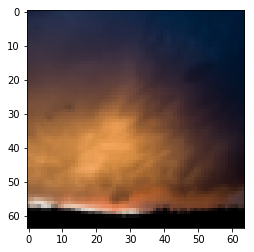

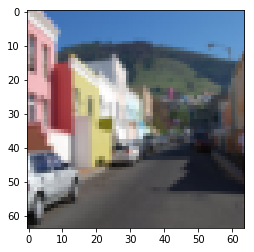

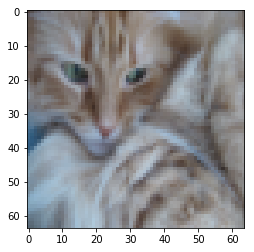

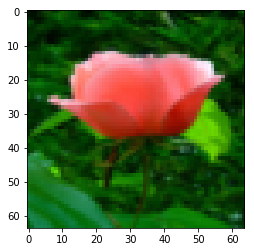

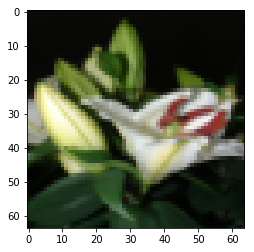

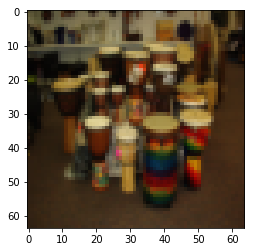

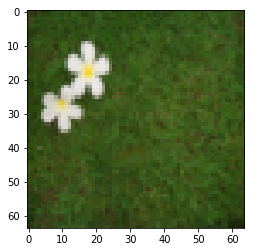

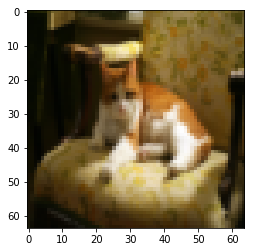

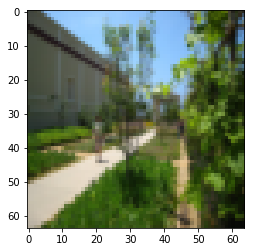

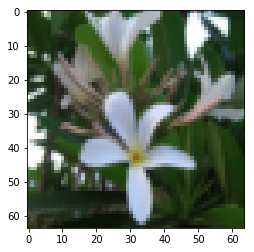

In [5]:
#IMPLEMENTE O CÓDIGO AQUI
for i in range(10):
    plt.figure()
    plt.imshow(X_train[i])

## Construindo a Topologia da Rede

## 1.4. Instruções:

- Faça a normalização dos dados de ENTRADA dos conjuntos de treinamento e teste pelo maior valor de pixel (255)

In [6]:
#CÉLULA KE-LIB-03
np.random.seed(4)
tf.set_random_seed(13)

#IMPLEMENTE O CÓDIGO AQUI (2 linhas)
X_train = X_train / 255
X_test = X_test / 255


## 1.5. Instruções:

- Faça o ajuste de dimensionalidade do tensor de entrada para 1 dimensão (flatenning)

**Nota:** não esqueça que a quantidade de entradas da rede será dada pelo tensor de entrada 'achatado em 1 dimensão' será dada por: $ 64 \cdot 64 \cdot 3 = 12288$

**Nota:** É possível redimensionar um tensor de N dimensões com o comando reshape, na forma:

    X_train_flatten = X_train.reshape(X_train.shape[0], -1)

In [7]:
#CÉLULA KE-LIB-04
#IMPLEMENTE O CÓDIGO AQUI (2 linhas)
X_train_flatten = X_train.reshape(X_train.shape[0], -1)
X_test_flatten  = X_test.reshape(X_test.shape[0], -1)
X_test_flatten

array([[0.61960784, 0.40784314, 0.3254902 , ..., 0.67843137, 0.50196078,
        0.43137255],
       [0.45098039, 0.43137255, 0.43529412, ..., 0.67058824, 0.69019608,
        0.72941176],
       [1.        , 0.99215686, 0.99607843, ..., 0.52156863, 0.39607843,
        0.4745098 ],
       ...,
       [0.16078431, 0.18431373, 0.32941176, ..., 0.71764706, 0.55294118,
        0.45490196],
       [0.07058824, 0.07058824, 0.0627451 , ..., 0.56470588, 0.5372549 ,
        0.42352941],
       [0.52156863, 0.63921569, 0.29411765, ..., 0.01960784, 0.08627451,
        0.01960784]])

## 1.6. Instruções:

- Verifique as dimensoes dos vetores X_train_flatten e y_train_flatten

In [8]:
#IMPLEMENTE O CÓDIGO AQUI (2 linhas)
X_train_flatten.shape
y_train.shape

(1, 209)

## 1.7. Instruções:

- Construa uma topologia de uma Rede Neural Densa com 2 camadas:

        layers_dims = [12288, 20, 1] # modelo de 2 camadas densas

Dados da topologia:
- Otimizador **RMSProp**
- Função de ativação da camada intermediaria: **ReLu** 
- Função de ativação da camada de saída: **Sigmoid** 
- Utilize treinamento em lote com **batch_size= 19**
- Limite o treinamento a **2500** épocas
- Função de Perda (Loss): **binary_crossentropy** (estamos lidando com classificação binária)

In [9]:
#CÉLULA KE-LIB-05
layers_dims = [12288, 20, 1] # modelo de 2 camadas densas

tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

#Limpa o modelo previamente usado, senão irá acumular camadas
K.backend.clear_session()

#Inicializador
init = K.initializers.glorot_uniform()

#IMPLEMENTE O CÓDIGO AQUI

#Criando o otimizador
theOptimizer = K.optimizers.rmsprop()

#Construindo o modelo (topologia)
model = K.models.Sequential()

#Exemplo de input_shape na camada de entrada da rede
# model = Sequential()
# model.add(Dense(32, input_shape=(16,)))
# o modelo irá receber como entrada arrays no formato (*, 16)
# e como saída terá arrays no formato (*, 32)

#Rede densa
model.add(K.layers.Dense(units=20, input_dim=12288, kernel_initializer=init, activation='relu'))
model.add(K.layers.Dense(units=1, kernel_initializer=init, activation='sigmoid'))


# Compile o modelo - IMPLEMENTE O CÓDIGO AQUI    
model.compile(loss='binary_crossentropy', optimizer=theOptimizer, metrics=['acc'])


## 1.8. Instruções:

- Execute o treinamento da rede com o comando no formato

        h = model.fit(x=X_train_flatten, y=y_train.T, batch_size=batch_size, epochs=max_epochs, verbose=1)
        
**Nota:** Pelo formato dos dados o valor de entrada deve ser inserido na forma **[N_amostras, N_Entradas]** enquanto o vetor de saída deve ser inserido no formato **[N_amostras, N_saidas]**

In [10]:
#CÉLULA KE-LIB-06
#IMPLEMENTE O CÓDIGO AQUI
batch_size = 19
max_epochs = 2500

print("Iniciando treinamento... ")
#IMPLEMENTE O CÓDIGO AQUI
h = model.fit(x=X_train_flatten, y=y_train.T, batch_size=batch_size, epochs=max_epochs, verbose=1)

print("Treinamento finalizado \n")

Iniciando treinamento... 
Epoch 1/2500
209/209 [==============================] - 2s 11ms/step - loss: 5.1952 - acc: 0.6364
Epoch 2/2500
209/209 [==============================] - 0s 445us/step - loss: 5.1609 - acc: 0.6268
Epoch 3/2500
209/209 [==============================] - 0s 445us/step - loss: 5.4429 - acc: 0.6555
Epoch 4/2500
209/209 [==============================] - 0s 540us/step - loss: 3.3090 - acc: 0.5120
Epoch 5/2500
209/209 [==============================] - 0s 478us/step - loss: 1.2925 - acc: 0.6268
Epoch 6/2500
209/209 [==============================] - 0s 445us/step - loss: 1.2222 - acc: 0.5981
Epoch 7/2500
209/209 [==============================] - 0s 406us/step - loss: 1.5839 - acc: 0.5359
Epoch 8/2500
209/209 [==============================] - 0s 392us/step - loss: 1.0270 - acc: 0.6746
Epoch 9/2500
209/209 [==============================] - 0s 416us/step - loss: 1.2849 - acc: 0.6077
Epoch 10/2500
209/209 [==============================] - 0s 406us/step - loss: 1.534

## 1.9. Instruções:

- Faça a verificação dos resultados dos conjuntos de **treinamento E teste** a partir do comando

        eval = model.evaluate(X_train_flatten, y_train.T, verbose=0)

**Nota:**  observe que o comando acima faz a validação do conjunto de treinamento apenas. Além disso, o formato dos dados de entrada segue o mesmo padrão utilizado no comando de treinamento

In [11]:
#CÉLULA KE-LIB-07
#IMPLEMENTE O CÓDIGO AQUI
eval = model.evaluate(X_train_flatten, y_train.T, verbose=0)
print("Erro médio do conjunto de treinamento: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

eval = model.evaluate(X_test_flatten, y_test.T, verbose=0)
print("Erro médio do conjunto de teste: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

Erro médio do conjunto de treinamento: Perda 0.0000, acuracia 100.0000
Erro médio do conjunto de teste: Perda 3.8793, acuracia 62.0000


# <center> Atividade 2 - Rede Neural Densa com 2 camadas ocultas </center>

## 2.1. Instruções:

- Construa uma nova topologia de rede com 4 camadas:
- Refaça o treinamento e compare os resultados

    layers_dims = [12288, 20, 7, 5, 1] # modelo de 4 camadas densas
    
Dados da topologia:
- Otimizador **RMSProp**
- Função de ativação da primeira camada oculta: **ReLu** 
- Função de ativação da segunda camada oculta: **ReLu** 
- Função de ativação da terceira camada oculta: **ReLu** 
- Função de ativação da camada de saída: **Sigmoid** 
- Utilize treinamento em lote com **batch_size= 19**
- Limite o treinamento a **2500** épocas
- Função de Perda (Loss): **binary_crossentropy** (estamos lidando com classificação binária)    

In [12]:
X_train, y_train, X_test, y_test, classes = loadDatasets()

X_train = X_train / 255
X_test = X_test / 255

X_train_flatten = X_train.reshape(X_train.shape[0], -1)   # The "-1" makes reshape flatten the remaining dimensions
X_test_flatten  = X_test.reshape(X_test.shape[0], -1)

In [13]:
#CÉLULA KE-LIB-08
layers_dims = [12288, 20, 7, 5, 1] # modelo de 4 camadas densas

tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

#Limpa o modelo previamente usado, senão irá acumular camadas
K.backend.clear_session()

#Inicializador
init = K.initializers.glorot_uniform()

#IMPLEMENTE O CÓDIGO AQUI
#Criando o otimizador
theOptimizer = K.optimizers.rmsprop()

#Construindo o modelo (topologia)
model = K.models.Sequential()

#Rede Densa - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Dense(units=20,input_dim=12288, kernel_initializer=init, activation='relu'))
model.add(K.layers.Dense(units=7, kernel_initializer=init, activation='relu'))
model.add(K.layers.Dense(units=5, kernel_initializer=init, activation='relu'))
model.add(K.layers.Dense(units=1, kernel_initializer=init, activation='sigmoid'))

#Compile o modelo - IMPLEMENTE O CÓDIGO AQUI
model.compile(loss='binary_crossentropy', optimizer=theOptimizer, metrics=['acc'])

In [14]:
#CÉLULA KE-LIB-09
#IMPLEMENTE O CÓDIGO AQUI
batch_size = 19
max_epochs = 2500

print("Iniciando treinamento... ")
#IMPLEMENTE O CÓDIGO AQUI
h = model.fit(x=X_train_flatten, y=y_train.T, batch_size=batch_size, epochs=max_epochs, verbose=1)

print("Treinamento finalizado \n")

Iniciando treinamento... 
Epoch 1/2500
209/209 [==============================] - 0s 2ms/step - loss: 0.8634 - acc: 0.6364
Epoch 2/2500
209/209 [==============================] - 0s 516us/step - loss: 0.6645 - acc: 0.6555
Epoch 3/2500
209/209 [==============================] - 0s 512us/step - loss: 0.6484 - acc: 0.6555
Epoch 4/2500
209/209 [==============================] - 0s 435us/step - loss: 0.6474 - acc: 0.6411
Epoch 5/2500
209/209 [==============================] - 0s 450us/step - loss: 0.6364 - acc: 0.6699
Epoch 6/2500
209/209 [==============================] - 0s 459us/step - loss: 0.6184 - acc: 0.6603
Epoch 7/2500
209/209 [==============================] - 0s 497us/step - loss: 0.6191 - acc: 0.6651
Epoch 8/2500
209/209 [==============================] - 0s 507us/step - loss: 0.5977 - acc: 0.6651
Epoch 9/2500
209/209 [==============================] - 0s 512us/step - loss: 0.6129 - acc: 0.6794
Epoch 10/2500
209/209 [==============================] - 0s 469us/step - loss: 0.5926

In [15]:
#CÉLULA KE-LIB-10
#IMPLEMENTE O CÓDIGO AQUI
eval = model.evaluate(X_train_flatten, y_train.T, verbose=0)
print("Erro médio do conjunto de treinamento: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

eval = model.evaluate(X_test_flatten, y_test.T, verbose=0)
print("Erro médio do conjunto de teste: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

Erro médio do conjunto de treinamento: Perda 0.0453, acuracia 99.5215
Erro médio do conjunto de teste: Perda 2.6560, acuracia 66.0000


# <center> Atividade 3 - Rede Neural Convolucional com 6 camadas </center>

## 3.1. Instruções:

Construa uma topologia de rede CONVOLUCIONAL da seguinte forma:

- Otimizador **Adam ou RMSProp**

    - 1 Camada Convolucional (Conv2D) com 32 Filtros, strides= (1,1) e padding='same' com função de ativação **ReLu**
    - 1 Camada Convolucional (Conv2D) com 64 Filtros, strides= (1,1) e padding='same' com função de ativação **ReLu**
    - 1 Camada MaxPooling2D com janela (2,2)
    - 1 Função de Dropout de 25% (0,25)

    - 1 Função *Flatten*
    - 1 Camada densa com 100 unidades e função de ativação **ReLu**
    - 1 Função de Dropout de 50% (0,5)
    - 1 Camada densa com 10  unidades e função de ativação **ReLu**
    - 1 Camada densa com 1   unidade  e função de ativação **Sigmoid**

- Utilize treinamento em lote com **batch_size= 19**
- Limite o treinamento a **50** épocas
- Função de Perda (Loss): **binary_crossentropy** (estamos lidando com classificação binária)    

In [18]:
X_train, y_train, X_test, y_test, classes = loadDatasets()

image_shape = (64,64,3)

X_train = X_train.reshape(-1, 64, 64, 3)
X_train = X_train / 255

X_test = X_test.reshape(-1, 64, 64, 3)
X_test = X_test / 255

### Para inicializar uma CNN, utilize um comando no padrão

        model.add(K.layers.Conv2D(filters=32, kernel_size=(3, 3), strides=(1,1), padding='same', kernel_initializer=init, activation='relu', input_shape=image_shape))

**Nota:** observe que o parametro input_shape indica a tupla referente às dimensoes da imagem (64 x 64 x 3 canais) e este parâmetro deve ser usado **APENAS NA PRIMEIRA camada da CNN** (e ignorado nas demais camadas do modelo)

In [19]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, LSTM, BatchNormalization
from keras.callbacks import TensorBoard
from keras.callbacks import ModelCheckpoint
from keras.optimizers import adam
from tensorflow.keras.optimizers import RMSprop


#CÉLULA KE-LIB-11
layers_dims = [12288, 20, 7, 5, 1] # modelo de 4 camadas densas

tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

#Limpa o modelo previamente usado, senão irá acumular camadas
K.backend.clear_session()

#Inicializador
init = K.initializers.glorot_uniform()

#Criando o otimizador
#IMPLEMENTE O CÓDIGO AQUI
theOptimizer = K.optimizers.Adam()

#Construindo o modelo (topologia)
model = K.models.Sequential()

#Camada convolucional - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Conv2D(filters=32, kernel_size=(3, 3), strides=(1,1), padding='same', kernel_initializer=init, activation='relu', input_shape=image_shape))

#Camada convolucional - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Conv2D(filters=64, kernel_size=(3, 3), strides=(1,1), padding='same', kernel_initializer=init, activation='relu'))

#MaxPooling - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.MaxPooling2D(pool_size=(2, 2))) 

#Dropout de 25% na camada anterior - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Dropout(0.25))

#Flatten para entrada da rede densa - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Flatten())

#Camada densa - IMPLEMENTE O CÓDIGO AQUI     
model.add(K.layers.Dense(units=100, kernel_initializer=init, activation='relu'))
#Dropout de 50% na camada anterior 
model.add(K.layers.Dropout(0.5))

model.add(K.layers.Dense(units=10, kernel_initializer=init, activation='relu'))
model.add(K.layers.Dense(units=1, kernel_initializer=init, activation='sigmoid'))

#Compile o modelo - IMPLEMENTE O CÓDIGO AQUI binary_crossentropy
model.compile(loss='binary_crossentropy', optimizer = theOptimizer, metrics=['acc'])


In [20]:
#CÉLULA KE-LIB-12

#IMPLEMENTE O CÓDIGO AQUI
batch_size = 19
max_epochs = 50

print("Iniciando treinamento... ")
h = model.fit(x=X_train, y=y_train.T, batch_size=batch_size, epochs=max_epochs, verbose=1)

print("Treinamento finalizado \n")
    


Iniciando treinamento... 
Epoch 1/50
209/209 [==============================] - 4s 18ms/step - loss: 0.6305 - acc: 0.6029
Epoch 2/50
209/209 [==============================] - 0s 2ms/step - loss: 0.5179 - acc: 0.6651
Epoch 3/50
209/209 [==============================] - 0s 2ms/step - loss: 0.4590 - acc: 0.6938
Epoch 4/50
209/209 [==============================] - 0s 2ms/step - loss: 0.4036 - acc: 0.7368
Epoch 5/50
209/209 [==============================] - 0s 2ms/step - loss: 0.4079 - acc: 0.7943
Epoch 6/50
209/209 [==============================] - 0s 2ms/step - loss: 0.3761 - acc: 0.8565
Epoch 7/50
209/209 [==============================] - 0s 2ms/step - loss: 0.3072 - acc: 0.8947
Epoch 8/50
209/209 [==============================] - 0s 2ms/step - loss: 0.2503 - acc: 0.9139
Epoch 9/50
209/209 [==============================] - 0s 2ms/step - loss: 0.2680 - acc: 0.8900
Epoch 10/50
209/209 [==============================] - 0s 2ms/step - loss: 0.1762 - acc: 0.9474
Epoch 11/50
209/209 [=

In [21]:
#CÉLULA KE-LIB-13
#IMPLEMENTE O CÓDIGO AQUI
eval = model.evaluate(X_train, y_train.T, verbose=0)
print("Erro médio do conjunto de treinamento: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

eval = model.evaluate(X_test, y_test.T, verbose=0)
print("Erro médio do conjunto de teste: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

Erro médio do conjunto de treinamento: Perda 0.0000, acuracia 100.0000
Erro médio do conjunto de teste: Perda 1.0553, acuracia 82.0000


É possível visualizar o gráfico de evolução do erro ao longo do treinamento a partir do seguinte código:

    plt.plot(range(len(h.history['loss'])), h.history['loss'])
    
**Nota:** a variável 'h' é a variável que foi retornada pelo comando *model.fit(...)*

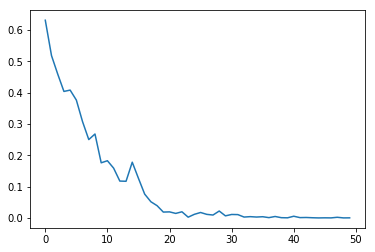

In [22]:
#IMPLEMENTE O CÓDIGO AQUI (1 linha)
plt.plot(range(len(h.history['loss'])), h.history['loss'])

# Compare os resultados obtidos com a Rede Convolucional comparada às Redes Neurais das Atividades 1 e 2

## Com a rede convolucional de 6 camadas, o erro caiu praticamente pela metade e a acurácia do conjunto de teste subiu 20% diminuindo o overfitting

## 3.2. Instruções:

Refaça o treinamento com a topologia acima, **ELIMINANDO a função de Dropout de 50% da Camada densa**

- Otimizador **Adadelta**

    - 1 Camada Convolucional (Conv2D) com 32 Filtros, strides= (1,1) e padding='same' com função de ativação **ReLu**
    - 1 Camada Convolucional (Conv2D) com 64 Filtros, strides= (1,1) e padding='same' com função de ativação **ReLu**
    - 1 Camada MaxPooling2D com janela (2,2)
    - 1 Função de Dropout de 25% (0,25)

    - 1 Função *Flatten*
    - 1 Camada densa com 100 unidades e função de ativação **ReLu**
    - <strike> 1 Função de Dropout de 50% (0,5) </strike>
    - 1 Camada densa com 10  unidades e função de ativação **ReLu**
    - 1 Camada densa com 1   unidade  e função de ativação **Sigmoid**

- Utilize treinamento em lote com **batch_size= 19**
- Limite o treinamento a **50** épocas
- Função de Perda (Loss): **binary_crossentropy** (estamos lidando com classificação binária)    

# Compare os resultados obtidos.

In [27]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, LSTM, BatchNormalization
from keras.callbacks import TensorBoard
from keras.callbacks import ModelCheckpoint
from keras.optimizers import adam
from tensorflow.keras.optimizers import RMSprop


#CÉLULA KE-LIB-11
layers_dims = [12288, 20, 7, 5, 1] # modelo de 4 camadas densas

tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

#Limpa o modelo previamente usado, senão irá acumular camadas
K.backend.clear_session()

#Inicializador
init = K.initializers.glorot_uniform()

#Criando o otimizador
#IMPLEMENTE O CÓDIGO AQUI
theOptimizer = K.optimizers.Adam()

#Construindo o modelo (topologia)
model = K.models.Sequential()

#Camada convolucional - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Conv2D(filters=32, kernel_size=(3, 3), strides=(1,1), padding='same', kernel_initializer=init, activation='relu', input_shape=image_shape))

#Camada convolucional - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Conv2D(filters=64, kernel_size=(3, 3), strides=(1,1), padding='same', kernel_initializer=init, activation='relu'))

#MaxPooling - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.MaxPooling2D(pool_size=(2, 2))) 

#Dropout de 25% na camada anterior - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Dropout(0.25))

#Flatten para entrada da rede densa - IMPLEMENTE O CÓDIGO AQUI
model.add(K.layers.Flatten())

#Camada densa - IMPLEMENTE O CÓDIGO AQUI     
model.add(K.layers.Dense(units=100, kernel_initializer=init, activation='relu'))
#Dropout de 50% na camada anterior retirado
#model.add(K.layers.Dropout(0.5))

model.add(K.layers.Dense(units=10, kernel_initializer=init, activation='relu'))
model.add(K.layers.Dense(units=1, kernel_initializer=init, activation='sigmoid'))

#Compile o modelo - IMPLEMENTE O CÓDIGO AQUI binary_crossentropy
model.compile(loss='binary_crossentropy', optimizer = theOptimizer, metrics=['acc'])


In [28]:
#CÉLULA KE-LIB-12

#IMPLEMENTE O CÓDIGO AQUI
batch_size = 19
max_epochs = 50

print("Iniciando treinamento... ")
h = model.fit(x=X_train, y=y_train.T, batch_size=batch_size, epochs=max_epochs, verbose=1)

print("Treinamento finalizado \n")
    


Iniciando treinamento... 
Epoch 1/50
209/209 [==============================] - 2s 12ms/step - loss: 0.7722 - acc: 0.6268
Epoch 2/50
209/209 [==============================] - 0s 2ms/step - loss: 0.5606 - acc: 0.6555
Epoch 3/50
209/209 [==============================] - 0s 2ms/step - loss: 0.4803 - acc: 0.6555
Epoch 4/50
209/209 [==============================] - 0s 2ms/step - loss: 0.4336 - acc: 0.6651
Epoch 5/50
209/209 [==============================] - 0s 2ms/step - loss: 0.4047 - acc: 0.7273
Epoch 6/50
209/209 [==============================] - 0s 2ms/step - loss: 0.3769 - acc: 0.8182
Epoch 7/50
209/209 [==============================] - 0s 2ms/step - loss: 0.3413 - acc: 0.8708
Epoch 8/50
209/209 [==============================] - 0s 2ms/step - loss: 0.3160 - acc: 0.8947
Epoch 9/50
209/209 [==============================] - 0s 2ms/step - loss: 0.2731 - acc: 0.9282
Epoch 10/50
209/209 [==============================] - 0s 2ms/step - loss: 0.1977 - acc: 0.9426
Epoch 11/50
209/209 [=

In [29]:
#CÉLULA KE-LIB-13
#IMPLEMENTE O CÓDIGO AQUI
eval = model.evaluate(X_train, y_train.T, verbose=0)
print("Erro médio do conjunto de treinamento: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

eval = model.evaluate(X_test, y_test.T, verbose=0)
print("Erro médio do conjunto de teste: Perda {0:.4f}, acuracia {1:.4f}".format(eval[0], eval[1]*100))

Erro médio do conjunto de treinamento: Perda 0.0000, acuracia 100.0000
Erro médio do conjunto de teste: Perda 1.0839, acuracia 80.0000


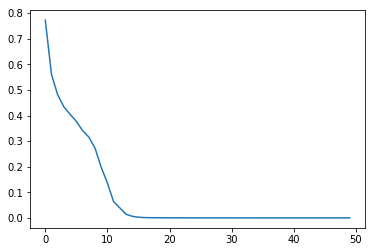

In [30]:
plt.plot(range(len(h.history['loss'])), h.history['loss'])

## Com a rede convolucional sem a camada de dropout, o resultado final foi praticamente o mesmo, porém analisando o gráfico, verifica-se uma diferença dos valores de erro ao longo do treinamento, com a camada de dropout o erro oscila bastante fazendo com que o gráfico fique serrilhado e começa estabilizar a partir da época 20, sem a camada de dropout o gráfico fica mais suave e se estabiliza a partir da época 10, portanto neste caso, na minha opinião, não é viável o uso da camada de dropout na rede de 6 camadas ocultas, pois mesmo sem ela diminuiu o overfitting.